# Escaped Asteroid Analysis
The run_log_analysis python script summarises the hdf5 log files into an escaped_asteroids pandas DataFrame. This DataFrame has details of the parameter and time that the asteroid exceeds the various parameters that are monitored. 

In [133]:
import datetime as datetime

import pandas as pd
import numpy as np
import h5py as h5

import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm


In [149]:

pa_mvc3 = pd.read_hdf('../../asteroid_data/sim_data/mvc_3/inputs/clone_assignments.h5')
ea_mvc3 = pd.read_hdf('../../asteroid_data/sim_data/mvc_3/escaped_asteroids.h5')


In [5]:
print(pa_mvc3.sort_values(['sim_no', 'particle_number']).tail())

         ast_name                     particle_types  sim_no  particle_number
38088  2000 RV111  [Xcm, Ycm, Zcm, VXcm, VYcm, VZcm]   19043               11
57133       P_426  [Xcm, Ycm, Zcm, VXcm, VYcm, VZcm]   19043               12
19044      488807              [X, Y, Z, VX, VY, VZ]   19044               10
38089  2000 RV111              [X, Y, Z, VX, VY, VZ]   19044               11
57134       P_426              [X, Y, Z, VX, VY, VZ]   19044               12


In [6]:
ea_mvc3.describe()

,particle_number,parameter,parameter_value,integration_year
count,75.000000,75.000000,75.000000,7.500000e+01
mean,11.333333,6.733333,2.837129,9.146455e+08
std,0.875080,0.759326,3.982359,6.691453e+08
min,10.000000,6.000000,0.000000,1.192378e+08
25%,10.000000,6.000000,0.348073,3.081744e+08
50%,12.000000,7.000000,0.566209,6.592810e+08
75%,12.000000,7.000000,4.918580,1.476477e+09
max,12.000000,8.000000,16.978478,2.098705e+09


In [7]:
print(f"Venus Ceres Mercurious escaped asteroids:{(ea_mvc3['ast_name']+ea_mvc3['vectors']).nunique()}")


Venus Ceres Mercurious escaped asteroids:35


In [10]:
ea_mvc3.sort_values(by=['ast_name', 'vectors']).head(20)

,ast_name,vectors,sim_no,particle_number,parameter,parameter_value,integration_year
27,16794,XcpYcpZcmVXcmVYcmVZcm,00145,10,6,4.138013,1.391716e+09
30,16794,XcpYcpZcmVXcmVYcmVZcm,00145,10,7,0.346992,1.343713e+09
32,16794,XcpYcpZcmVXcmVYcmVZcm,00145,10,8,0.666367,1.379904e+09
2,16794,XcpYcpZcmVXcmVYcmVZcp,00144,10,6,4.878547,1.730194e+09
5,16794,XcpYcpZcmVXcmVYcmVZcp,00144,10,7,0.352138,1.722528e+09
7,16794,XcpYcpZcmVXcmVYcmVZcp,00144,10,8,0.622371,1.730005e+09
41,16794,XcpYcpZcmVXcpVYcpVZcp,00138,10,6,4.991017,1.380909e+09
44,16794,XcpYcpZcmVXcpVYcpVZcp,00138,10,7,0.355418,1.373998e+09
46,16794,XcpYcpZcmVXcpVYcpVZcp,00138,10,8,0.857450,1.380847e+09
16,16794,XcpYcpZcpVXcmVYcpVZcp,00134,10,7,0.349238,1.467681e+09


In [82]:
print(ea_mvc3.groupby(['parameter']).max())
print(ea_mvc3.groupby(['parameter']).min())

          ast_name                vectors sim_no  particle_number   
parameter                                                           
6           499395  XcpYcpZcpVXcpVYcpVZcp  00149               12  \
7           493333  XcpYcpZcpVXcpVYcpVZcp  00149               12   
8           493333  XcpYcpZcpVXcpVYcpVZcp  00145               12   

           parameter_value  integration_year  
parameter                                     
6                16.978478      2.098705e+09  
7                 0.391927      2.051078e+09  
8                 0.935241      2.096694e+09  
          ast_name                vectors sim_no  particle_number   
parameter                                                           
6            16794  XcmYcmZcmVXcpVYcmVZcm  00059               10  \
7            16794  XcmYcmZcmVXcpVYcmVZcm  00059               10   
8            16794  XcmYcmZcmVXcpVYcmVZcm  00059               10   

           parameter_value  integration_year  
parameter                 

In [148]:
ea_mvc3.groupby(['ast_name']).count()

,vectors,sim_no,particle_number,parameter,parameter_value,integration_year
ast_name,,,,,,
16794,20,20,20,20,20,20
2001 QO310,1,1,1,1,1,1
2002 FL44,44,44,44,44,44,44
493333,3,3,3,3,3,3
499395,7,7,7,7,7,7


In [141]:
escapee_years = ea_mvc3.loc[ea_mvc3.parameter == 6][['ast_name', 'vectors', 'integration_year']]
escapee_years.sort_values(by=['integration_year'])


,ast_name,vectors,integration_year
9,2002 FL44,XcpYcpZcpVXcmVYcpVZcm,1.236360e+08
57,2002 FL44,XcpYcpZcpVXcpVYcmVZcm,1.815674e+08
43,2002 FL44,XcpYcpZcmVXcpVYcpVZcp,2.021135e+08
4,2002 FL44,XcpYcpZcmVXcmVYcmVZcp,2.041870e+08
73,2002 FL44,XcpYcpZcmVXcmVYcpVZcm,2.396872e+08
12,2002 FL44,XcpYcpZcmVXcpVYcmVZcp,2.434571e+08
52,2002 FL44,XcpYcpZcmVXcmVYcpVZcp,3.090540e+08
48,2002 FL44,XcpYcmZcpVXcpVYcmVZcm,3.177877e+08
23,2002 FL44,XcpYcpZcpVXcpVYcpVZcp,3.210550e+08
29,2002 FL44,XcpYcpZcmVXcmVYcmVZcm,3.283435e+08


(array([9., 4., 3., 1., 0., 3., 5., 1., 6., 2.]),
 array([1.96772860e+07, 5.11114843e+07, 8.25456825e+07, 1.13979881e+08,
        1.45414079e+08, 1.76848277e+08, 2.08282476e+08, 2.39716674e+08,
        2.71150872e+08, 3.02585070e+08, 3.34019269e+08]),
 <BarContainer object of 10 artists>)

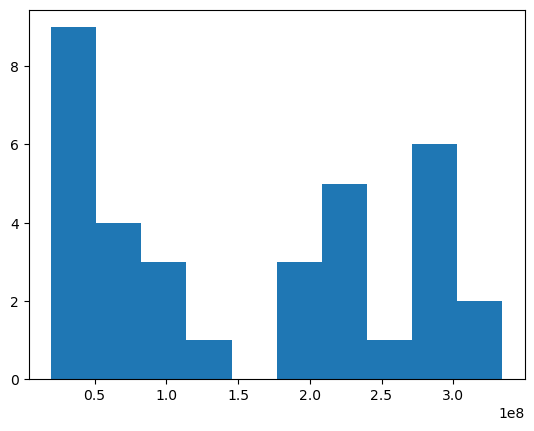

In [26]:
plt.hist(escapee_years.integration_year/(2*np.pi))

In [28]:
path = '../../asteroid_data/luthera_family.h5'
luth_fam = pd.read_hdf(path)
luth_fam['irad'] = np.arcsin(luth_fam['sineI_P'])
luth_fam['ideg'] = np.degrees(luth_fam['irad'])
mag_h = 17
p_v = 0.0387
luth_fam['diam']= ((1329 * 10**(-luth_fam['abs_mag']/5)) * (p_v ** (-0.5)))
print(luth_fam.head())

  ast_name  abs_mag       a_P       e_P   sineI_P family_id      irad   
0     1303     9.48  3.219248  0.121842  0.322276      1303  0.328133  \
1    11911    11.80  3.210027  0.132169  0.330567      1303  0.336904   
2    16794    13.45  3.229767  0.120773  0.321221      1303  0.327019   
3    17840    12.46  3.227073  0.122213  0.322861      1303  0.328751   
4    26558    13.15  3.194646  0.115763  0.319342      1303  0.325035   

        ideg       diam  
0  18.800624  85.836005  
1  19.303194  29.489642  
2  18.736782  13.793342  
3  18.836035  21.760531  
4  18.623137  15.836875  


In [168]:
escaped_asts = ea_mvc3.ast_name.unique()
escaped_asts = [x.replace(' ','') for x in escaped_asts]

escaped_asts

['2002FL44', '16794', '499395', '493333', '2001QO310']

In [171]:
luth_fam[luth_fam.ast_name.isin(escaped_asts)==True]

,ast_name,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam
2,16794,13.45,3.229767,0.120773,0.321221,1303,0.327019,18.736782,13.793342
293,493333,15.71,3.227294,0.122424,0.323283,1303,0.329197,18.861583,4.871576
295,499395,16.54,3.216326,0.134521,0.330983,1303,0.337345,19.328450,3.324065
586,2001QO310,16.80,3.191888,0.113097,0.315359,1303,0.320835,18.382488,2.948964
588,2002FL44,16.38,3.212787,0.135076,0.330553,1303,0.336889,19.302344,3.578240


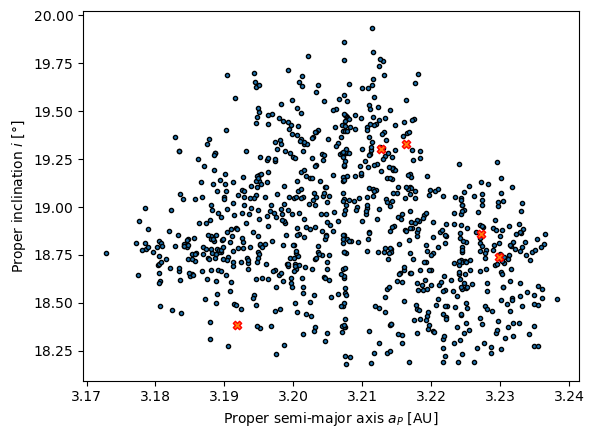

In [172]:
plt.scatter(data=luth_fam[luth_fam.ast_name.isin(escaped_asts)==False], x='a_P',y='ideg', edgecolors='black', marker=".")
plt.scatter(data=luth_fam[luth_fam.ast_name.isin(escaped_asts)], x='a_P',y='ideg', edgecolors='red', marker="X")
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper inclination $i$ [$\degree$]")
plt.show()

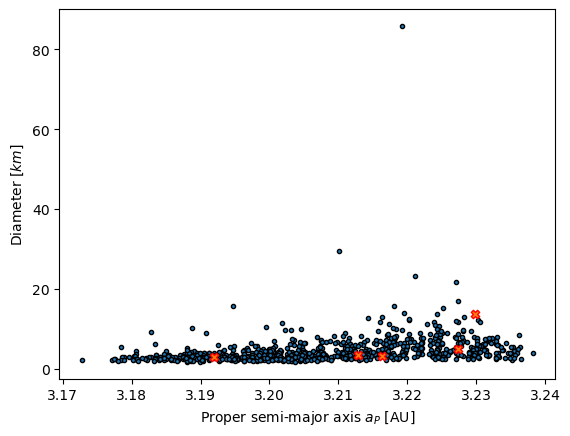

In [173]:
plt.scatter(data=luth_fam[luth_fam.ast_name.isin(escaped_asts)==False], x='a_P',y='diam', edgecolors='black', marker=".")
plt.scatter(data=luth_fam[luth_fam.ast_name.isin(escaped_asts)], x='a_P',y='diam', edgecolors='red', marker="X")
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Diameter [$km$]")
plt.show()

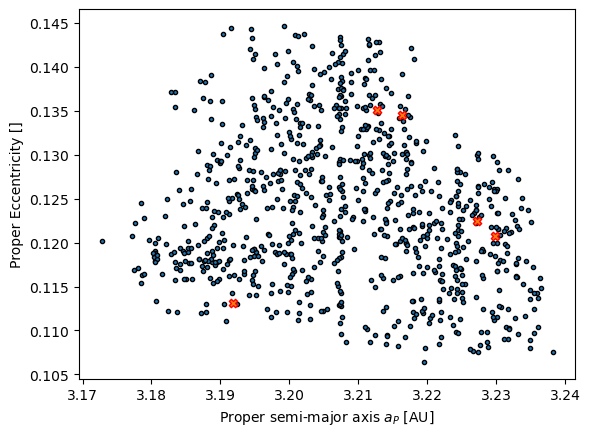

In [174]:
plt.scatter(data=luth_fam[luth_fam.ast_name.isin(escaped_asts)==False], x='a_P',y='e_P', edgecolors='black', marker=".")
plt.scatter(data=luth_fam[luth_fam.ast_name.isin(escaped_asts)], x='a_P',y='e_P', edgecolors='red', marker="X")
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Eccentricity []")
plt.show()

In [175]:
test_fam = luth_fam.copy()
test_fam = test_fam.set_index('ast_name')

In [177]:
esc_fam 

,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam
ast_name,,,,,,,,
16794,13.45,3.229767,0.120773,0.321221,1303,0.327019,18.736782,13.793342
493333,15.71,3.227294,0.122424,0.323283,1303,0.329197,18.861583,4.871576
499395,16.54,3.216326,0.134521,0.330983,1303,0.337345,19.328450,3.324065


In [178]:
#test_fam['integration_year'] = 0
#test_fam['graph_symbol'] = '.'

mean_escape = escapee_years.groupby('ast_name').mean('integration_year')

mean_escape.index = [x.replace(' ','') for x in mean_escape.index]

mean_escape

,integration_year
16794,1.607105e+09
2001QO310,1.857115e+09
2002FL44,4.699476e+08
493333,1.856801e+09
499395,1.590284e+09


In [179]:
test_fam['integration_year'] = mean_escape
test_fam = test_fam.fillna(value={'integration_year': 0})
test_fam['graph_symbol'] = '.'
test_fam.loc[test_fam['integration_year']!=0,['graph_symbol']] = 'X'
test_fam

,abs_mag,a_P,e_P,sineI_P,family_id,irad,ideg,diam,integration_year,graph_symbol
ast_name,,,,,,,,,,
1303,9.48,3.219248,0.121842,0.322276,1303,0.328133,18.800624,85.836005,0.000000e+00,.
11911,11.80,3.210027,0.132169,0.330567,1303,0.336904,19.303194,29.489642,0.000000e+00,.
16794,13.45,3.229767,0.120773,0.321221,1303,0.327019,18.736782,13.793342,1.607105e+09,X
17840,12.46,3.227073,0.122213,0.322861,1303,0.328751,18.836035,21.760531,0.000000e+00,.
26558,13.15,3.194646,0.115763,0.319342,1303,0.325035,18.623137,15.836875,0.000000e+00,.
...,...,...,...,...,...,...,...,...,...,...
2013BN95,17.17,3.194082,0.114092,0.317706,1303,0.323309,18.524250,2.486964,0.000000e+00,.
2013CE106,17.04,3.199622,0.138950,0.332601,1303,0.339060,19.426722,2.640399,0.000000e+00,.
2013CG92,17.20,3.194881,0.135663,0.334094,1303,0.340644,19.517454,2.452842,0.000000e+00,.


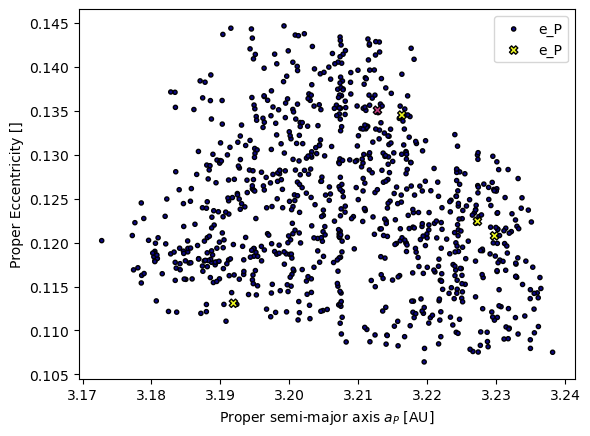

In [184]:
for graph_symbol, m_fam in test_fam.groupby('graph_symbol'):
    plt.scatter(data=m_fam, x='a_P',y='e_P', edgecolors='black', marker=graph_symbol, 
                c=cm.plasma(m_fam['integration_year']/1.0e9))
    
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper Eccentricity []")
plt.legend()
plt.show()